## **1. Carga del dataset**

Vamos a cargar las imágenes del dataset, asegurándonos de que todas tengan la misma resolución y estén en escala de grises.

In [30]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [31]:
DATASET_DIR = "data/images"
IMG_SIZE = 64
TOTAL_IMAGES = 30000

images = np.empty((TOTAL_IMAGES, IMG_SIZE, IMG_SIZE), dtype=np.uint8)

In [32]:
loaded_count = 0

for i in range(TOTAL_IMAGES):
    filename = f"{i}.jpg"
    filepath = os.path.join(DATASET_DIR, filename)
    
    # Lectura en escala de grises (se evalua en grises)
    img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
    
    if img is None:
        raise FileNotFoundError(f"No se pudo cargar la imagen: {filepath}")
    
    # Garantizamos resolución de 64x64 
    if img.shape != (IMG_SIZE, IMG_SIZE):
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
        
    images[i] = img
    loaded_count += 1

print(f"Total cargado: {loaded_count} imágenes")

Total cargado: 30000 imágenes


In [33]:
# Comprobaciones numéricas y dimensionales
print(f"Forma del tensor: {images.shape}")          # Esperado: (30000, 64, 64)
print(f"Tipo de dato:     {images.dtype}")          # Esperado: uint8
print(f"Valor mínimo:     {images.min()}")          # Esperado: 0 o cercano 
print(f"Valor máximo:     {images.max()}")          # Esperado: 255 o cercano 

Forma del tensor: (30000, 64, 64)
Tipo de dato:     uint8
Valor mínimo:     0
Valor máximo:     255


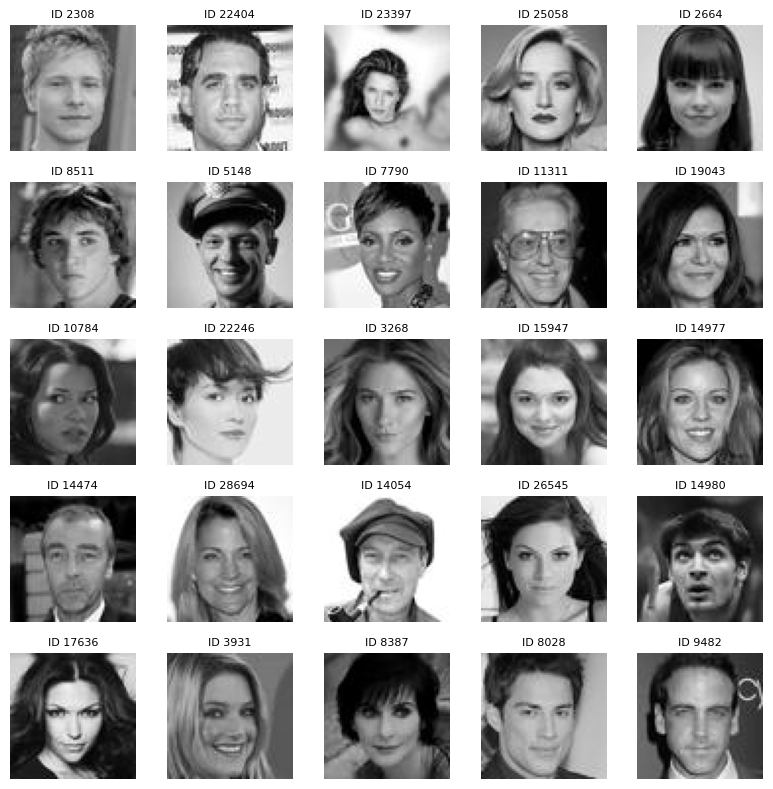

In [34]:
# Visualización de una cuadrícula de 5x5 imágenes
fig, axes = plt.subplots(5, 5, figsize=(8, 8))
np.random.seed(42)
sample_indices = np.random.choice(TOTAL_IMAGES, size=25, replace=False)

for ax, idx in zip(axes.flat, sample_indices):
    ax.imshow(images[idx], cmap="gray", vmin=0, vmax=255)
    ax.axis("off")
    ax.set_title(f"ID {idx}", fontsize=8)

plt.tight_layout()
plt.show()

---

## **2. Implementación del VAE Baseline**

In [35]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

In [36]:
# Semillas para reproducibilidad
SEED = 1234
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [37]:
# Preprocesamiento y split (90% Train / 10% Val)

x_data = images.astype("float32") / 255.0
x_data = np.expand_dims(x_data, axis=-1)  # (30000, 64, 64, 1)

val_size = int(0.10 * len(x_data))
indices = np.random.permutation(len(x_data))
train_idx, val_idx = indices[val_size:], indices[:val_size]

x_train = x_data[train_idx]
x_val = x_data[val_idx]

print(f"Conjunto de entrenamiento: {x_train.shape}")
print(f"Conjunto de validación:    {x_val.shape}")

Conjunto de entrenamiento: (27000, 64, 64, 1)
Conjunto de validación:    (3000, 64, 64, 1)


In [38]:
# Reparametrización: z = mu + sigma * epsilon
class Sampling(layers.Layer):
    """Aplica el truco de reparametrización: z = mu + sigma * epsilon."""
    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = tf.shape(z_mean)[0]
        dim = tf.shape(z_mean)[1]
        epsilon = tf.random.normal(shape=(batch, dim))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

In [39]:
# Arquitectura del VAE Baseline
LATENT_DIM = 64

# Encoder
encoder_inputs = keras.Input(shape=(64, 64, 1), name="encoder_input")
x = layers.Conv2D(32, 3, strides=2, padding="same")(encoder_inputs)
x = layers.LeakyReLU(negative_slope=0.2)(x)

x = layers.Conv2D(64, 3, strides=2, padding="same")(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

x = layers.Conv2D(128, 3, strides=2, padding="same")(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

x = layers.Flatten()(x)
z_mean = layers.Dense(LATENT_DIM, name="z_mean")(x)
z_log_var = layers.Dense(LATENT_DIM, name="z_log_var")(x)
z = Sampling()([z_mean, z_log_var])

encoder = keras.Model(encoder_inputs, [z_mean, z_log_var, z], name="encoder")
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 64, 64, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 32, 32,    │        320 │ encoder_input[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_14      │ (None, 32, 32,    │          0 │ conv2d_8[0][0]    │
│ (LeakyReLU)         │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 16, 16,    │     18,496 │ leaky_re_lu_14[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_15      │ (None, 16, 16,    │          0 │ conv2d_9[0][0]    │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 8, 8, 128) │     73,856 │ leaky_re_lu_15[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_16      │ (None, 8, 8, 128) │          0 │ conv2d_10[0][0]   │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_2 (Flatten) │ (None, 8192)      │          0 │ leaky_re_lu_16[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 64)        │    524,352 │ flatten_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 64)        │    524,352 │ flatten_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling_2          │ (None, 64)        │          0 │ z_mean[0][0],     │
│ (Sampling)          │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,141,376 (4.35 MB)

 Trainable params: 1,141,376 (4.35 MB)

 Non-trainable params: 0 (0.00 B)

In [40]:
# Decoder
latent_inputs = keras.Input(shape=(LATENT_DIM,), name="decoder_input")
x = layers.Dense(8 * 8 * 128)(latent_inputs)
x = layers.LeakyReLU(negative_slope=0.2)(x)
x = layers.Reshape((8, 8, 128))(x)

x = layers.Conv2DTranspose(64, 3, strides=2, padding="same")(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

x = layers.Conv2DTranspose(32, 3, strides=2, padding="same")(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

x = layers.Conv2DTranspose(16, 3, strides=2, padding="same")(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

decoder_outputs = layers.Conv2D(1, 3, strides=1, padding="same", activation="sigmoid")(x)

decoder = keras.Model(latent_inputs, decoder_outputs, name="decoder")
decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8192)           │       532,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_17 (LeakyReLU)      │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_2 (Reshape)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_6              │ (None, 16, 16, 64)     │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_18 (LeakyReLU)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_7              │ (None, 32, 32, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_19 (LeakyReLU)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_8              │ (None, 64, 64, 16)     │         4,624 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_20 (LeakyReLU)      │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 64, 64, 1)      │           145 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 629,505 (2.40 MB)

 Trainable params: 629,505 (2.40 MB)

 Non-trainable params: 0 (0.00 B)

In [41]:
# Modelo VAE completo
class VAE(keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.total_loss_tracker = keras.metrics.Mean(name="total_loss")
        self.reconstruction_loss_tracker = keras.metrics.Mean(name="rec_loss")
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker,
        ]

    def _compute_losses(self, data):
        # Desempaquetar
        if isinstance(data, tuple):
            data = data[0]

        z_mean, z_log_var, z = self.encoder(data)
        reconstruction = self.decoder(z)

        # Pérdida de reconstrucción 
        eps = 1e-7
        rec_clipped = tf.clip_by_value(reconstruction, eps, 1.0 - eps)
        bce = -(data * tf.math.log(rec_clipped) + (1.0 - data) * tf.math.log(1.0 - rec_clipped))
        rec_loss_per_sample = tf.reduce_sum(bce, axis=[1, 2, 3])
        rec_loss = tf.reduce_mean(rec_loss_per_sample)

        # Divergencia KL analítica (beta = 1)
        kl_loss_per_sample = -0.5 * tf.reduce_sum(
            1.0 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), 
            axis=1
        )
        kl_loss = tf.reduce_mean(kl_loss_per_sample)

        total_loss = rec_loss + kl_loss
        return total_loss, rec_loss, kl_loss

    def train_step(self, data):
        with tf.GradientTape() as tape:
            total_loss, rec_loss, kl_loss = self._compute_losses(data)
        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(rec_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {
            "loss": self.total_loss_tracker.result(),
            "rec_loss": self.reconstruction_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }

    def test_step(self, data):
        total_loss, rec_loss, kl_loss = self._compute_losses(data)
        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(rec_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {
            "loss": self.total_loss_tracker.result(),
            "rec_loss": self.reconstruction_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }

In [42]:
# Compilacion y entrenamiento 
vae = VAE(encoder, decoder)
vae.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3))

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    )
]

EPOCHS = 60
BATCH_SIZE = 128

history = vae.fit(
    x_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(x_val, x_val),
    callbacks=callbacks,
    shuffle=True
)

Epoch 1/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 14s 59ms/step - kl_loss: 16.2433 - loss: 2567.5022 - rec_loss: 2551.2590 - val_kl_loss: 20.7648 - val_loss: 2300.6990 - val_rec_loss: 2279.9343
Epoch 2/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 11s 54ms/step - kl_loss: 16.6366 - loss: 2288.4575 - rec_loss: 2271.8208 - val_kl_loss: 9.9723 - val_loss: 2249.7605 - val_rec_loss: 2239.7883
Epoch 3/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 12s 55ms/step - kl_loss: 9.0875 - loss: 2250.1589 - rec_loss: 2241.0713 - val_kl_loss: 7.4876 - val_loss: 2239.2903 - val_rec_loss: 2231.8030
Epoch 4/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 11s 54ms/step - kl_loss: 7.1468 - loss: 2236.9353 - rec_loss: 2229.7883 - val_kl_loss: 6.0165 - val_loss: 2227.4194 - val_rec_loss: 2221.4031
Epoch 5/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 12s 55ms/step - kl_loss: 6.2975 - loss: 2229.7356 - rec_loss: 2223.4380 - val_kl_loss: 5.8211 - val_loss: 2224.1067 - val_rec_loss: 2218.2854
Epoch 6/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 12s 57ms/step - kl_loss: 5.7890 - loss: 2224.18

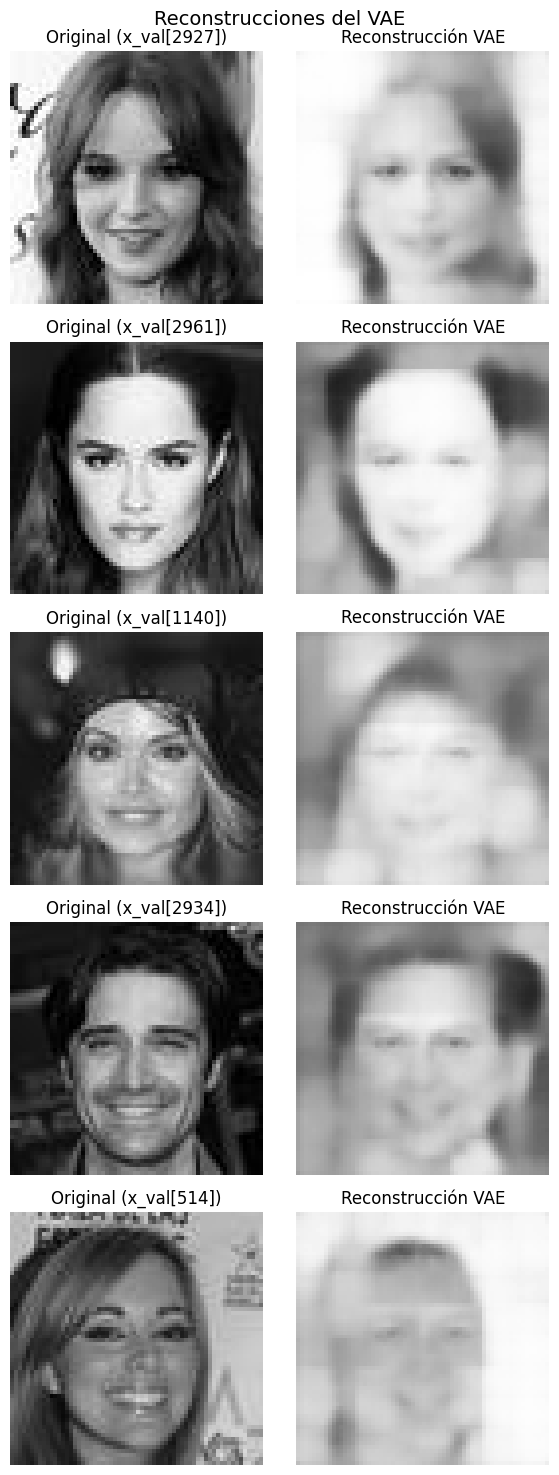

In [49]:
# Comparación de reconstrucciones del VAE sobre las mismas cinco imágenes
COMPARISON_SEED = SEED
comparison_rng = np.random.default_rng(COMPARISON_SEED)
comparison_indices = comparison_rng.choice(len(x_val), size=5, replace=False)
x_val_samples = x_val[comparison_indices]

z_mean_val, _, _ = encoder.predict(x_val_samples, verbose=0)
vae_reconstructions = decoder.predict(z_mean_val, verbose=0)

fig, axes = plt.subplots(5, 2, figsize=(6, 15))
fig.suptitle("Reconstrucciones del VAE", fontsize=14)

for row, (original, reconstruction, sample_index) in enumerate(
    zip(x_val_samples, vae_reconstructions, comparison_indices)
):
    axes[row, 0].imshow(original[..., 0], cmap="gray", vmin=0, vmax=1)
    axes[row, 0].set_title(f"Original (x_val[{sample_index}])")
    axes[row, 1].imshow(reconstruction[..., 0], cmap="gray", vmin=0, vmax=1)
    axes[row, 1].set_title("Reconstrucción VAE")
    axes[row, 0].axis("off")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

In [43]:
# Mejores métricas obtenidas durante el entrenamiento
metrics_history = history.history
best_epoch = int(np.argmin(metrics_history["val_loss"]))

print(f"Mejor época según val_loss: {best_epoch + 1}")
print(f"Train loss:      {metrics_history['loss'][best_epoch]:.4f}")
print(f"Validation loss: {metrics_history['val_loss'][best_epoch]:.4f}")
print(f"Train rec_loss:  {metrics_history['rec_loss'][best_epoch]:.4f}")
print(f"Val rec_loss:    {metrics_history['val_rec_loss'][best_epoch]:.4f}")
print(f"Train kl_loss:   {metrics_history['kl_loss'][best_epoch]:.4f}")
print(f"Val kl_loss:     {metrics_history['val_kl_loss'][best_epoch]:.4f}")

Mejor época según val_loss: 35
Train loss:      2196.7996
Validation loss: 2204.9836
Train rec_loss:  2193.1748
Val rec_loss:    2201.4753
Train kl_loss:   3.6245
Val kl_loss:     3.5085


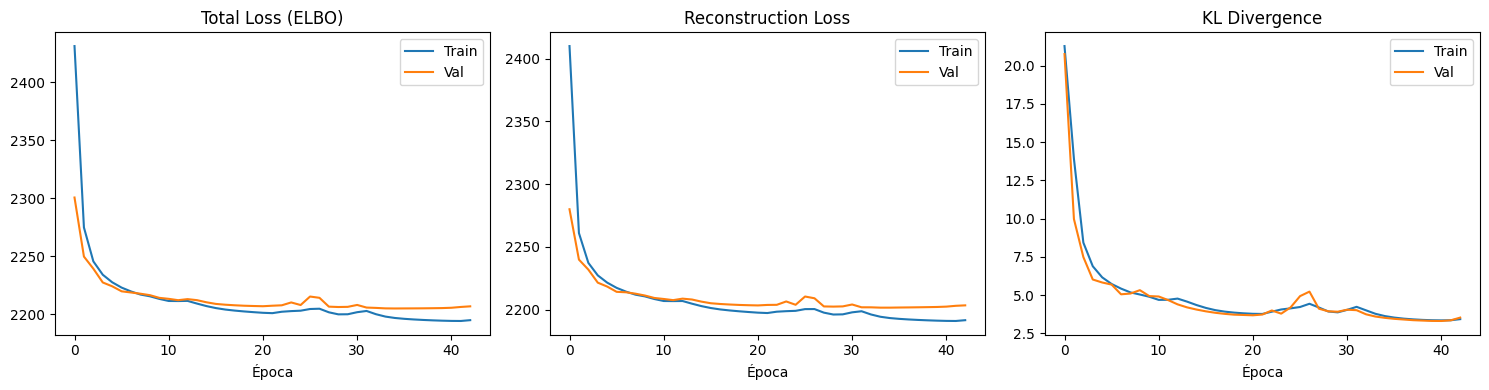

In [44]:
# Plot del entrenamiento
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(history.history["loss"], label="Train")
axes[0].plot(history.history["val_loss"], label="Val")
axes[0].set_title("Total Loss (ELBO)")
axes[0].set_xlabel("Época")
axes[0].legend()

axes[1].plot(history.history["rec_loss"], label="Train")
axes[1].plot(history.history["val_rec_loss"], label="Val")
axes[1].set_title("Reconstruction Loss")
axes[1].set_xlabel("Época")
axes[1].legend()

axes[2].plot(history.history["kl_loss"], label="Train")
axes[2].plot(history.history["val_kl_loss"], label="Val")
axes[2].set_title("KL Divergence")
axes[2].set_xlabel("Época")
axes[2].legend()

plt.tight_layout()
plt.show()

---

## **3. Creación de una submission**

In [45]:
import pandas as pd

In [46]:
# Muestreo de 200 vectores latentes para generar imágenes
N_SAMPLES = 200
LATENT_DIM = 64
SAMPLE_SEED = 1234

np.random.seed(SAMPLE_SEED)
z_samples = np.random.normal(
    loc=0.0,
    scale=1.0,
    size=(N_SAMPLES, LATENT_DIM)
).astype(np.float32)

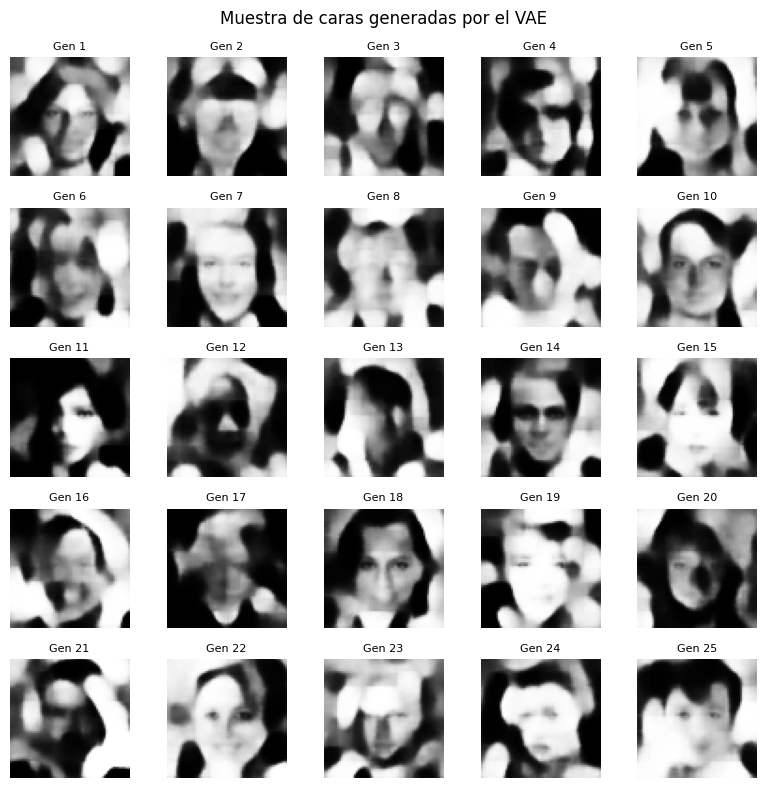

In [47]:
# Decodificación y conversión a uint8 [0, 255]
generated_imgs = vae.decoder.predict(
    z_samples,
    batch_size=N_SAMPLES,
    verbose=0
)

generated_imgs = np.clip(
    np.round(generated_imgs * 255.0), 0, 255
).astype(np.uint8)

generated_imgs = np.squeeze(generated_imgs, axis=-1)

fig, axes = plt.subplots(5, 5, figsize=(8, 8))
fig.suptitle("Muestra de caras generadas por el VAE", fontsize=12)

for i, ax in enumerate(axes.flat):
    ax.imshow(generated_imgs[i], cmap="gray", vmin=0, vmax=255)
    ax.axis("off")
    ax.set_title(f"Gen {i + 1}", fontsize=8)

plt.tight_layout()
plt.show()

In [48]:
# Generación de la submission del VAE
flat_pixels = generated_imgs.reshape(N_SAMPLES, IMG_SIZE * IMG_SIZE)

df_submission = pd.DataFrame(
    flat_pixels,
    columns=[str(i) for i in range(IMG_SIZE * IMG_SIZE)]
)

df_submission.insert(0, "Usage", "Public")
df_submission.insert(0, "ID", range(1, N_SAMPLES + 1))

csv_filename = "submission_vae.csv"
df_submission.to_csv(csv_filename, index=False)
print(f"Archivo guardado como '{csv_filename}'")

print(f"Forma esperada:  ({N_SAMPLES}, {IMG_SIZE * IMG_SIZE + 2})")
print(f"Forma obtenida:  {df_submission.shape}")
print(f"Rango de IDs:    {df_submission['ID'].min()} a {df_submission['ID'].max()}")
print(f"Valores únicos en 'Usage': {df_submission['Usage'].unique()}")
print(f"Primeras 5 columnas de cabecera: {list(df_submission.columns[:5])}")
print(f"Últimas 3 columnas de cabecera:  {list(df_submission.columns[-3:])}")
print(f"Valores nulos en el dataframe:   {df_submission.isnull().sum().sum()}")

Archivo guardado como 'submission_vae.csv'
Forma esperada:  (200, 4098)
Forma obtenida:  (200, 4098)
Rango de IDs:    1 a 200
Valores únicos en 'Usage': ['Public']
Primeras 5 columnas de cabecera: ['ID', 'Usage', '0', '1', '2']
Últimas 3 columnas de cabecera:  ['4093', '4094', '4095']
Valores nulos en el dataframe:   0


---

## **4. Evaluación FID del VAE**

La FID compara imágenes reales de validación con imágenes generadas por el AE. Es la métrica usada en la competición.

In [59]:
%pip install "torchmetrics[image]"

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [54]:
import torch

print("PyTorch:", torch.__version__)
print("MPS disponible:", torch.backends.mps.is_available())
print("Dispositivo FID:", torch.device)

PyTorch: 2.14.1
MPS disponible: True
Dispositivo FID: <class 'torch.device'>


In [ ]:
from torchmetrics.image.fid import FrechetInceptionDistance

FID_SEED = SEED
FID_BATCH_SIZE = 64
FID_NUM_IMAGES = min(len(x_val), 512)

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"


def prepare_images_for_fid(images):
    images = np.asarray(images)
    images = np.clip(images, 0.0, 1.0)
    images = (images * 255.0).round().astype(np.uint8)
    images = np.repeat(images, 3, axis=-1)
    images = np.transpose(images, (0, 3, 1, 2))
    return torch.from_numpy(images)


def calculate_fid(generated_images, real_images, batch_size=FID_BATCH_SIZE):
    fid = FrechetInceptionDistance(
        feature=2048,
        normalize=False
    ).to(device)

    real_images = prepare_images_for_fid(real_images)
    generated_images = prepare_images_for_fid(generated_images)

    with torch.inference_mode():
        for start in range(0, len(real_images), batch_size):
            fid.update(
                real_images[start:start + batch_size].to(device),
                real=True
            )

        for start in range(0, len(generated_images), batch_size):
            fid.update(
                generated_images[start:start + batch_size].to(device),
                real=False
            )

        return fid.compute().item()


real_images = x_val[:FID_NUM_IMAGES]
fid_rng = np.random.default_rng(FID_SEED)
z_vae_fid = fid_rng.normal(
    loc=0.0,
    scale=1.0,
    size=(FID_NUM_IMAGES, LATENT_DIM)
).astype(np.float32)
generated_vae_fid = decoder.predict(
    z_vae_fid,
    batch_size=FID_BATCH_SIZE,
    verbose=0
)

device = torch.device("cpu")

In [58]:
fid_vae = calculate_fid(
    generated_vae_fid,
    real_images,
    batch_size=FID_BATCH_SIZE
)
print(f"FID VAE ({FID_NUM_IMAGES} imágenes, dispositivo={device}): {fid_vae:.4f}")

FID VAE (512 imágenes, dispositivo=cpu): 233.3522
